Hands-On Workshops – WS 2026/27

# Ana I-1: Plots in Julia, Induktion

***

<div class="alert alert-block alert-danger">
Folgende Begriffe, Konzepte und Sätze sollten am Ende des Sheets verstanden sein:

<ul>   
    <li> Plots in Julia  </li>
<li>   
Vollständige Induktion</li>  
<li>   
Vollständige Induktion mit allgemeinem Startindex</li>  
    <li>   
Starke Induktion</li>  
        
 </ul>  
Bitte beachten Sie: Alle Quickchecks und Aufgaben müssen vollständig bearbeitet werden.
    
</div>

***



# Plots in Julia

Wir können Plots erstellen, um Daten oder Funktionen zu visualisieren und besser zu verstehen. Julia bietet verschiedene Bibliotheken, um z. B. line plots, scatter plots, bar plots und histograms zu erstellen.

Zuerst müssen wir `using Plots` benutzen, damit Julia das Plots-Package importiert.

In [1]:
using SymPy
using Plots # bitte führen Sie diese Zelle einmal mit Shift+Enter aus, damit das Paket geladen wird

In [33]:
x = symbols("x")
h = sin(x)

sin(x)

Um die Funktion $h$ zu visualisieren benutzen wir folgenden Befehl:

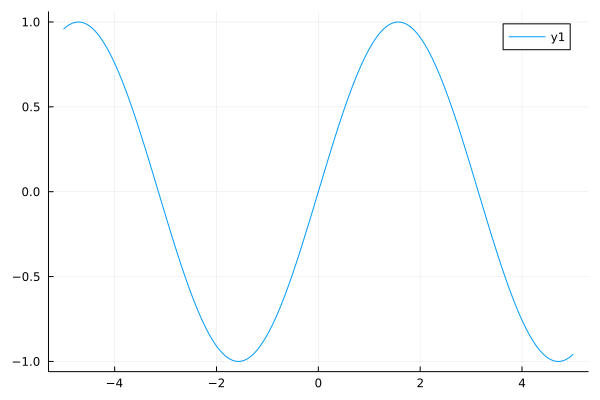

In [3]:
plot(h)

Dabei ist der Plot automatisch ein Liniendiagramm und Julia bestimmt selber, welcher Teil des Koordinatensystems genau geplottet wird.
Wir können auch bestimmen, welchen Teil wir sehen wollen, indem wir `xlim` und `ylim` verwenden und das gewünschte Intervall angeben.

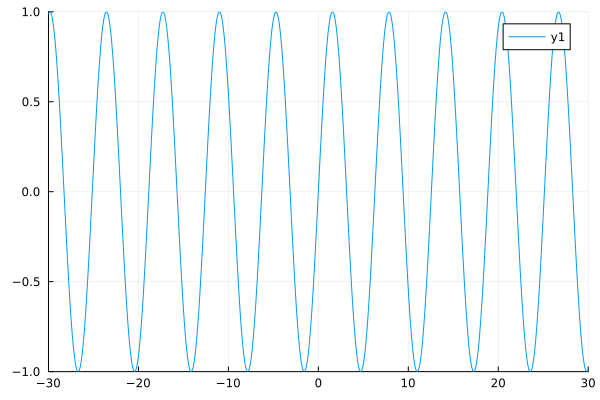

In [4]:
plot(h, xlim = (-30,30), ylim = (-1,1))

Wenn man möchte, kann man die Grafik mit den folgenden Befehlen beschriften. Die Reihenfolge spielt dabei keine Rolle.

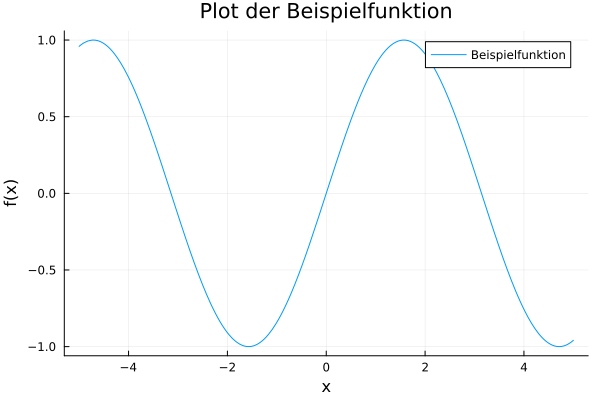

In [5]:
plot(h, label = "Beispielfunktion", xlabel = "x", ylabel = "f(x)", title = "Plot der Beispielfunktion")

Man kann auch einige kosmetische Veränderungen vornehmen, z. B. mit folgenden Befehlen:

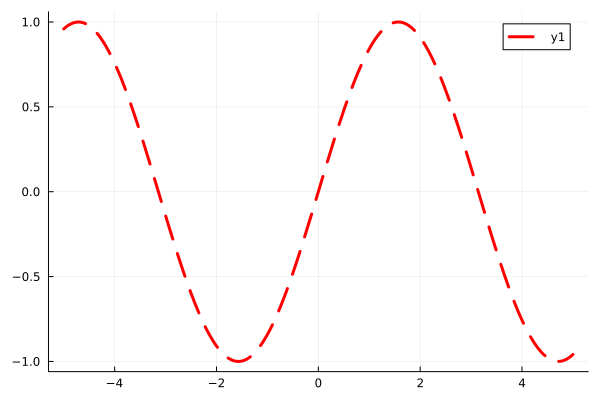

In [6]:
plot(h, linewidth = 3, linestyle =:dash, linecolor =:red)

Auch mehrere Funktionen sind in einem einzigen Plot darstellbar, indem bei der zweiten (und ggf. dritten, vierten, ...) Funktion das <code>plot</code> durch ein <code>plot!</code> ersetzt wird.

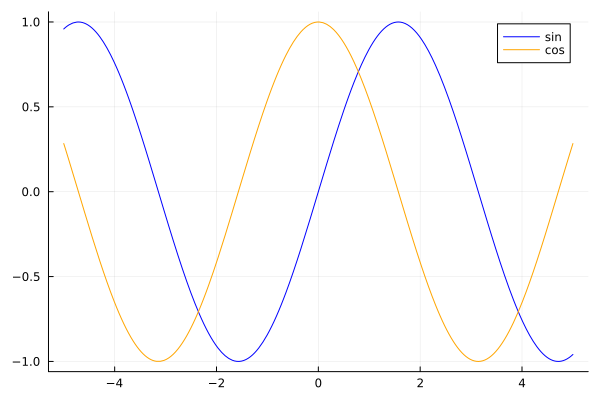

In [7]:
g = cos(x) #neue Funktion definieren

plot(h, linecolor =:blue, label = "sin")
plot!(g, linecolor =:orange, label = "cos") #man beachte das "!"

<div class="alert alert-block alert-success">
    
### Aufgabe 1
***
Plotten Sie folgende Funktionen in ein einziges Koordinatensystem:
<ul>
    <li> $f_1(x) = x^2 -10x + 16$ </li>
    <li> $f_2(x) = -x^2 + 15x - 50$ </li>
    <li> $f_3(x) = x^2 - 7x + 6$ </li>    
</ul>    
Nutzen Sie Liniendiagramme und sorgen Sie dafür, dass man die Funktionsgraphen gut unterscheiden kann und alle Nullstellen sichtbar sind.
    
</div>

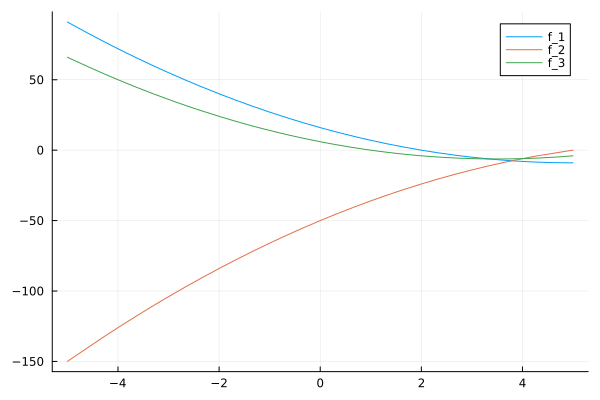

In [8]:
#LÖSUNG AUFGABE 1

f_1 = (x) -> x^2 - (10*x) + 16;
f_2 = (x) -> -x^2 + (15*x) - 50;
f_3 = (x) -> x^2 - (7*x) + 6;

plot(f_1, label = "f_1")
plot!(f_2, label = "f_2")
plot!(f_3, label = "f_3")

Julia kann nicht nur Liniendiagramme plotten. Auch Punktdiagramme sind darstellbar. Dazu benötigen wir zwei Arrays der gleichen Länge. Eins mit den Werten des Definitionsbereiches, das andere mit den dazugehörigen Bildern.

In [9]:
definitionsbereich = [0, 2, 4, 6, 8, 10]
bild = [2, 1, 0, 3, 5, 6]

6-element Vector{Int64}:
 2
 1
 0
 3
 5
 6

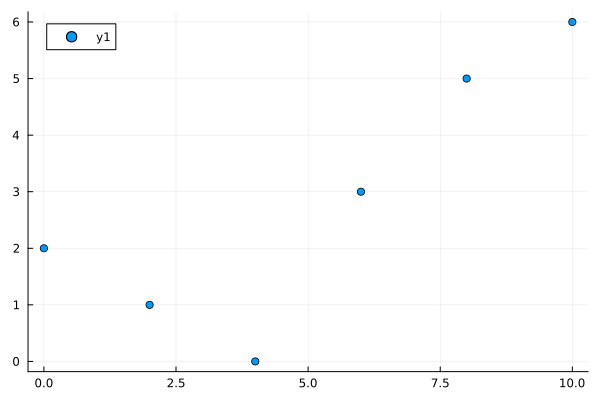

In [10]:
plot(definitionsbereich, bild, seriestype =:scatter)

Achten Sie darauf, zuerst das Array, welches auf die x-Achse aufgetragen werden soll, einzugeben, und dann das Array mit den Folgenwerten. Mit dem Stichwort `seriestype =:scatter` weiß Julia, dass ein Punktdiagramm entstehen soll. 
<br> Wir können statt Punkten auch andere Formen durch Verwendung des Befehls `shape` erzeugen. Natürlich sind die bereits eingeführten Befehle zur Beschriftung und kosmetischen Veränderung des Plots auch für Punktdiagramme verwendbar.

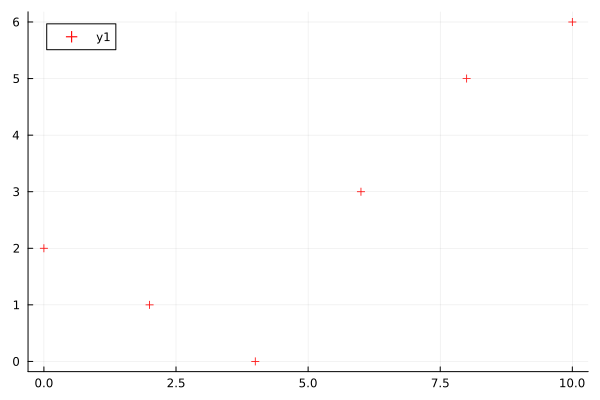

In [11]:
plot(definitionsbereich, bild, seriestype =:scatter, shape =:+, color=:red)

Im Folgenden definieren wir eine Folge und plotten diese mit einem Punktdiagramm.

In [12]:
n = symbols("n") 
a = (2n^2 - n + 1)/(n^2 + 2n) #Folgenvorschrift definieren 

   2        
2⋅n  - n + 1
────────────
   2        
  n  + 2⋅n  

In [13]:
x = [i for i = 1:10] #Man definiere x-Achsen-Daten in einem Array
y = [a(i) for i = 1:10] #Man definiere y-Achsen-Daten in einem Array

10-element Vector{Sym{PyCall.PyObject}}:
     2/3
     7/8
   16/15
   29/24
   46/35
   67/48
   92/63
  121/80
    14/9
 191/120

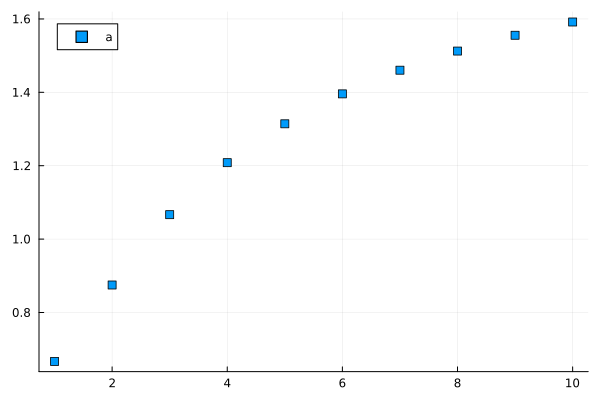

In [14]:
plot(x, y, seriestype =:scatter, shape =:rect, label = "a")

<div class="alert alert-block alert-success">
    
### Aufgabe 2
***
Plotten Sie jeweils für $n\in\{1,\ldots,n\}$ in ein einziges Koordinatensystem:
<ul>
    <li> $a_n=\sqrt{n}$ </li>
    <li> $b_n=n^{\frac{7}{20}}$ </li>
    <li> $c_n=\log(n)$ </li>    
</ul>    
Nutzen Sie Punktdiagramme und sorgen Sie dafür, dass man die Funktionsgraphen gut unterscheiden kann.
    
</div>

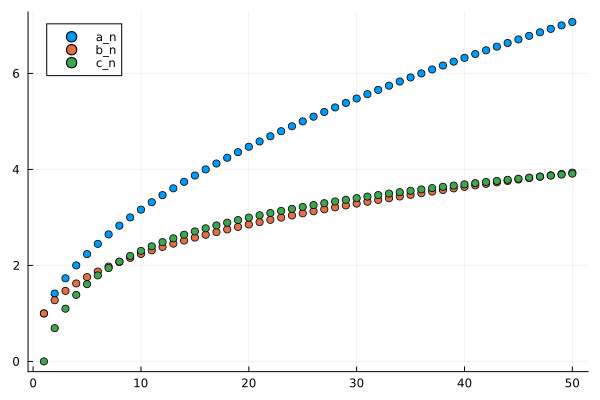

In [18]:
#LÖSUNG AUFGABE 2

n = 50;

a_n = [sqrt(i) for i = 1:n];
b_n = [i^(7//20) for i = 1:n];
c_n = [log(i) for i = 1:n];

definitions_b = [i for i = 1:n];

plot(definitions_b, a_n, label = "a_n", seriestype = "scatter")
plot!(definitions_b, b_n, label = "b_n", seriestype = "scatter")
plot!(definitions_b, c_n, label = "c_n", seriestype = "scatter")


***

# Induktion

[🎞️ Vollständige Induktion](https://youtu.be/UglHUECGGxA)

Wir kommen nun zum zweiten Teil des Sheets.

Eine wichtige Beweistechnik in der Mathematik ist das Prinzip der vollständigen Induktion. Dem zugrunde liegt folgende Eigenschaft der natürlichen Zahlen $\mathbb{N}$:


<div class="alert alert-block alert-info">
    <b> Induktionsprinzip </b> <br>
    Ist $M\subseteq\mathbb{N}$ eine Teilmenge mit den Eigenschaften 
    <ul> <li> $1 \in M$ </li>
        <li> für alle $n\in M$ gilt auch $n+1 \in M$ </li>
    </ul> 
    dann gilt $M=\mathbb{N}$.
</div>

Haben wir eine Aussage $A(n)$, die wir für alle $n \in \mathbb{N}$ zeigen möchten, dann erhalten wir mit $M=\{n\in\mathbb{N}:A(n)\;\mbox{gilt}\}$ folgende Beweisstrategie: Wir zeigen im Induktionsanfang (IA) zunächst, dass $A(1)$ gilt und im Induktionsschritt (IS) zeigen wir, dass wann immer $A(n)$ gilt, auch $A(n+1)$ wahr ist. Nach dem Induktionsprinzip gilt dann $M=\mathbb{N}$, d. h. die Aussage $A(n)$ gilt für alle $n\in \mathbb{N}$. 

<div class="alert alert-block alert-info">
    <b> Vollständige Induktion </b> <br>
    Um eine Aussage $A(n)$ für alle $n\in \mathbb{N}$ zu beweisen, genügt es zu zeigen
    <ul> <li> IA: $A(1)$ gilt </li>
        <li> IS: für alle $n\in \mathbb{N}$ gilt: $A(n)\Rightarrow A(n+1)$ </li>
    </ul> 

</div>

Es kann sinnvoll sein, zusätzlich zu IA und IS auch noch eine Induktionsvoraussetzung (IV) explizit aufzuschreiben, also dass $A(n)$ für ein beliebiges, aber festes $n\in\mathbb{N}$ gelte.

Man kann sich das Induktionsprinzip als eine (unendliche) Reihe von Dominosteinen vorstellen. Damit der Induktionsschritt gilt, müssen die Dominosteine nah genug aneinander stehen, sodass sichergestellt ist, dass wenn ein Stein umfällt immer auch der nächste umfällt. Der Induktionsanfang ist unverzichtbar, damit überhaupt ein erster Stein umfällt. <br>

Eine Visualisierung findet sich in folgender Grafik:

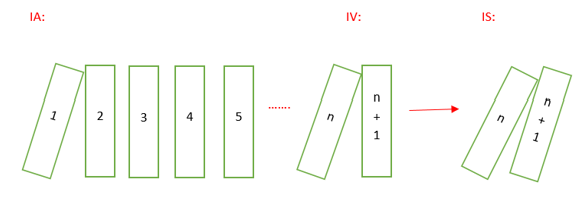

Schauen wir uns folgendes <b><u>Beispiel</u></b> an:

Wir wollen für alle $n\in \mathbb{N}$ zeigen, dass $6^{n-1}-1$ durch $5$ teilbar ist. Wir definieren dazu für alle $n\in \mathbb{N}$ die Aussage  $$A(n) : 5 \mid (6^n-1)$$

Dass die Aussage für die ersten paar natürlichen Zahlen gilt, lässt sich schnell mit Julia überprüfen, indem wir in folgendem Experiment den Rest beim Teilen durch $5$ berechnen und verifizieren, dass dieser gleich Null ist. 

In [19]:
for n=1:10
    println((6^n-1)%5==0)
end

true
true
true
true
true
true
true
true
true
true


Wir könnten dieses Experiment mit Julia nun auch noch für alle $n=1$ bis $100$ oder $1000$ etc. nachprüfen, doch beweist dies natürlich nicht die Aussage für <i>alle</i> natürlichen Zahlen. Das Experiment ist also nur ein Indiz dafür, dass unsere Aussage $A(n)$ für alle $n\in \mathbb{N}$ gelten könnte. 

Für den Induktionsbeweis beginnen wir mit dem <b>Induktionsanfang</b> 
> <b>(IA)</b> <br>    Sei $n=1$. Es gilt $$5\mid 5=(6^1-1),$$ also ist $A(1)$ wahr.


Wir fahren fort mit der <b>Induktionsvoraussetzung (IV)   </b>

> <b>(IV)</b> <br> Angenommen, es gelte die Aussage $A(n)$ für ein $n\in\mathbb{N}$, d.h. für dieses $n$ gelte: $5 \mid (6^n-1)$

Wichtig ist dabei, dass es sich hierbei um ein beliebiges, aber festes $n\in\mathbb{N}$ handelt. Nun kommt der <b>Induktionsschritt (IS)</b>:
    
> <b>(IS)</b> <br>  Zu zeigen ist, dass $A(n+1)$ gilt, d. h. dass $(6^{n+1}-1)$ dann ebenfalls durch $5$ teilbar ist:  $$6^{n+1}-1  = 6\cdot6^n-1=6\cdot(6^n-1)+6-1=6\cdot(6^n-1)+5$$
Der erste Summand ist ein Vielfaches von $6^n-1$ und ist nach Voraussetzung ($A(n)$ gilt) durch $5$ teilbar, und der zweite Summand $5$ ist ebenfalls durch $5$ teilbar, somit ist die gesamte rechte Seite durch $5$ teilbar. <div align="right"> ◼️ </div>

Um einen Induktionsbeweis zu führen, formen wir die Aussage $A(n+1)$ also so um, dass wir unsere Voraussetzung "$A(n)$ gilt" verwenden können. Im obigen Beweis war bekannt, dass $6^n-1$ durch $5$ teilbar ist, d. h. uns stand eine Information über die Zahl $6^n$ zur Verfügung und deshalb wurde im ersten Schritt $6^{n+1}$ zu $6\cdot6^n$ umgeformt.

Natürlich funktioniert vollständige Induktion ähnlich für Aussagen, in denen die Aussage $A(n)$ nur für fast alle $n\in \mathbb{N}$ wahr ist, d. h. es gibt höchstens endlich viele $m\in \mathbb{N}$, in denen $A(m)$ falsch ist, aber ab einem bestimmen Wert $n_0\in\mathbb{N}$ gilt $A(n)$ für alle $n\geq n_0$. 

<div class="alert alert-block alert-info">
    <b> Vollständige Induktion mit allgemeinem Startindex </b> <br>
    Um eine Aussage $A(n)$ für alle $n\in \mathbb{N}$ mit $n\geq n_0$ zu beweisen, genügt es zu zeigen
    <ul> <li> IA: $A(n_0)$ gilt </li>
        <li> IS: für alle $n\in \mathbb{N}$ mit $n\geq n_0$ gilt: $A(n)\Rightarrow A(n+1)$ </li>
    </ul> 
</div>

<div class="alert alert-block alert-success">
    
### Quickcheck 1
***
Nico und Susi fragen sich nach der Vorlesung: ,,Wenn ich eine Aussage $A(n)$ für alle $n\in\mathbb{N}$ per Induktion beweisen soll und dabei im Induktionsschritt so vorgehe, dass ich $A(n)$ erst für alle $n\in\mathbb{N}$ annehme, nur um $A(n+1)$ dann für alle $n\in\mathbb{N}$ zu folgern, habe ich doch eigentlich nichts bewiesen. Oder?'' Können Sie weiterhelfen?
    
</div>

### LÖSUNG QUICKCHECK 1

Man nimmt fuer ein festes aber beliebiges $n \in \mathbb{N}$, nicht alle.

<div class="alert alert-block alert-success">
    
### Quickcheck 2
***
<ul>
    Es sei $(a_n)_{n\geq 0}$ eine Folge von ganzen Zahlen, die wie folgt definiert ist: $a_0=1$, $a_1=4$ und
    <center>$a_{n+2}=2a_{n+1}-a_n$.</center>
    <li>a)<code>[Julia]</code> Berechnen Sie mit Julia die ersten 10-20 Terme von $(a_n)$ und stellen Sie eine Vermutung für $a_n$ auf. </li>
    <li>b) Beweisen Sie Ihre Vermutung mittels Induktion.</li>
    </ul>
    
</div>


### LÖSUNG QUICKCHECK 2

In [30]:
# why Julia, why 1-indexed?!!!!
a_n = zeros(Int, 20);
a_n[1] = 1;
a_n[2] = 4;

for i in 3:20
    a_n[i] = 2*a_n[i - 1] - a_n[i - 2];
end

println(a_n);



[1, 4, 7, 10, 13, 16, 19, 22, 25, 28, 31, 34, 37, 40, 43, 46, 49, 52, 55, 58]


### Vermutung $a_{n + 2}$ ist monoton wachsend

**Beweis**: 

**IA**: Fuer $n = 0$ ist die Vermutung wahr

**IV**: Es gelte fuer f.a.b. $n \in \mathbb{N}$ 

$$
    a_{n + 1} > a_{n}
$$

**IB**: Wir wollen zeigen 

$$
    a_{n + 2} > a_{n + 1}
$$

**IS**: 

\begin{align*}
    a_{n + 2} = 2a_{n + 1} - a_{n} &>  a_{n + 1} \\
    a_{n + 1} - a_{n} &> 0 \\
    a_{n + 1}  &>  a_{n} \\
\end{align*}

_QED_



<div class="alert alert-block alert-success">
    
### Quickcheck 3
***
Finden Sie den Fehler im folgenden Induktions"beweis" und erklären Sie auch anhand obigen Bilds mit den Dominosteinen, was schiefgeht: <br>
    Ist $V$ eine Vorlesung, so haben alle Hörer:innen am gleichen Tag Geburtstag. Dies kann durch Induktion über die Anzahl $n$ der Hörer:innen bewiesen werden:<br>
Ist $n=1$, so hat $V$ nur eine Hörer:in, also gilt die Behauptung. Die Aussage gelte nun für jede Vorlesung mit $n$ Hörer:innen. Sei $V$ eine Vorlesung mit $n+1$ Hörer:innen. Nun wird eine Hörer:in $A$ hinausgeschickt und nach Induktionsvoraussetzung haben dann alle verbleibenden Hörer:innen am gleichen Tag $t$ Geburtstag. Hörer:in $A$ darf wieder hereinkommen und wir schicken eine andere Hörer:in $B\neq A$ hinaus. Nun haben die verbleibenden Hörer:innen wieder nach Induktionsvoraussetzung alle am gleichen Tag Geburtstag, und dieser muss ja dann mit $t$ übereinstimmen. Damit haben $A$ und $B$ und alle anderen Hörer:innen am gleichen Tag $t$ Geburtstag.
    
</div>

### LÖSUNG QUICKCHECK 3

BRO what? 



<div class="alert alert-block alert-success">
    
### Aufgabe 3
***
In dieser Aufgabe soll gezeigt werden, dass für alle $n\in \mathbb{N}$ gilt:
    $$\sum\limits_{k=1}^{2n-1}(-1)^{k+1}k^2=n(2n-1) $$
    
<ul>
    <li> a) Stellen Sie $A(n)$ auf und zeige von Hand, dass $A(n)$ für $n=1,2,3$ gilt.
    </li>
      <li> b)<code>[Julia]</code> Überprüfen Sie in Julia mithilfe einer for-Schleife, dass $A(n)$ für alle $n\leq 20$ gilt. 
    </li> 
    <li> c) Beweisen Sie mit vollständiger Induktion, dass $A(n)$ für alle $n\in \mathbb{N}$ gilt. Achten Sie darauf, im Induktionsschritt sauber aufzuschreiben, was zu zeigen ist (insbesondere: was sagt $A(n+1)$ aus?).  
    </li> 
        <li> d) (freiwillig): Finden Sie einen Beweis der Aussage, der keine vollständige Induktion verwendet. 
    </li> 
    </ul>
    
</div>


### LÖSUNG AUFGABE 3

### a)

Zu zeigen ist, dass fuer alle \(n \in \mathbb{N}\) gilt:

$$
    \sum_{k=1}^{2n-1}(-1)^{k+1}k^2=n(2n-1)
$$

**n = 1**

$$
\sum_{k=1}^{1}(-1)^{k+1}k^2
=1^2=1=1(2\cdot 1-1)
$$

**n = 2**:

\begin{align*}
    \sum_{k=1}^{3}(-1)^{k+1}k^2
    &=1^2-2^2+3^2\\
    &=1-4+9\\
    &=6=2(2\cdot 2-1)
\end{align*}

**n = 3**:


\begin{align*}
    \sum_{k=1}^{5}(-1)^{k+1}k^2
    &=1^2-2^2+3^2-4^2+5^2\\
    &=1-4+9-16+25\\
    &=15=3(2\cdot 3-1)
\end{align*}


### c)

**IA**

$n=1$ gilt:

\begin{align*} 
    \sum_{k=1}^{2\cdot 1-1} (-1)^{k+1} k^2 &=1^2 \\
     &=1 \\
    &=1(2\cdot 1-1) 
\end{align*}

**IV**:

Es gelte für ein beliebiges, aber festes \\(n\in\mathbb{N}\\):

$$ 
    \sum_{k=1}^{2n-1}(-1)^{k+1}k^2=n(2n-1) 
$$

**IS**:

Wir wollen zeigen, dass

$$ 
    \sum_{k=1}^{2(n+1)-1}(-1)^{k+1}k^2 =(n+1)(2(n+1)-1) = 2n^2 + 3n + 1
$$

Ergo, 

\begin{align*}
    \sum_{k=1}^{2(n+1)-1}(-1)^{k+1}k^2 &= n(2n - 1) + (-1)^{2n + 1} (2n)^2 + (-1)^{2n + 2} (2n + 1)^2 \\
    &= n(2n - 1) -4n^2 + 4n^2  + 4n + 1 \\
    &= 2n^2 - n -4n^2 + 4n^2  + 4n + 1 \\
    &= 2n^2 + 3n + 1 \\
\end{align*}

_QED_


In [ ]:
### b

for n in 1:20
    lhs = sum((-1)^(k+1) * k^2 for k in 1:(2*n-1))
    rhs = n * (2*n-1)

    println("n = $n: ", lhs == rhs)
end

n = 1: true
n = 2: true
n = 3: true
n = 4: true
n = 5: true
n = 6: true
n = 7: true
n = 8: true
n = 9: true
n = 10: true
n = 11: true
n = 12: true
n = 13: true
n = 14: true
n = 15: true
n = 16: true
n = 17: true
n = 18: true
n = 19: true
n = 20: true


## Starke Induktion

Die starke Induktion zielt auf Anwendungen, in denen wir $A(n+1)$ allein mit dem Wissen von $A(n)$ nicht zeigen können, sondern auch noch auf $A(n-1), A(n-2),...,A(2),A(1)$ zurückgreifen müssen:

<div class="alert alert-block alert-info">
<b>Starkes Induktionsprinzip</b>
   Um eine Aussage $A(n)$ für alle $n\in \mathbb{N}$ zu beweisen, genügt es zu zeigen
    <ul> <li> IA: $A(1)$ gilt </li>
        <li> IS: für alle $n\in \mathbb{N}$ gilt: falls $A(k)$ für alle $k\in \mathbb{N}$ mit $k\leq n$ gilt, dann gilt auch $A(n+1)$ </li>
    </ul>    

</div>

Auch die starke Induktion kann mit allgemeinem Startindex $n_0$ verwendet werden.

<div class="alert alert-block alert-success">
    
### Aufgabe 4

Beweisen Sie anhand von starker Induktion die folgende Aussage:
<center> Jede natürliche Zahl $n\in\mathbb{N}$ mit $n\geq 2$ lässt sich als Produkt endlich vieler Primzahlen schreiben (dabei lassen wir auch zu, dass das Produkt nur aus einem einzelnen Faktor besteht).</center>
<i> Hinweis: </i> im Induktionsschritt bietet sich eine Fallunterscheidung an, ob $n+1$ eine Primzahl ist.
    
</div>


### LÖSUNG AUFGABE 4

**IA**: Fuer $n = 2$, $n = 3$, $n = 4$ die Aussage gilt, da die ersten zwei prim sind und 4 can als produkt von 2 mal zwei geschrieben werden.

**IV**: Man nehemen das fuer alle $k$ mit $2 \le k \le n$ natuerliche Zahlen die Aussage gilt.

**IS**: Sei $n + 1$ eine Primzahl, dann ist die Behauptung bewiesen. Fuer $n + 1$ nicht prim, laesst sich  $n + 1 = pq$ schreiben wo $p, q < n + 1$. Somit sind $p$ und $q$ in dem Bereich 
von 
$$2 \le k \le p, q \le n < n + 1$$

Ergo die aussage gilt fuer $p$ und $q$. Und da $n + 1$ ist gleich das Produkt von zwei Produkte aus Primzahlen. Somit ist die Aussage bewiesen.